# ¡Hola Jesus!

Mi nombre es Sofia Arboleda, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario de la revisora</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

# Sprint 6 · Proyecto integrado: tienda Ice
## Patrones de ventas de videojuegos para orientar la campaña de 2017

**Estudiante:** Jesús Alejandro Gómez Pérez  
**Escenario de decisión:** diciembre de 2016. No se incorporan resultados posteriores a 2016.  
**Alcance:** análisis exploratorio y contraste de hipótesis, no un modelo predictivo entrenado ni una estimación de beneficios.

### Objetivo

Identificar plataformas, géneros, reseñas y perfiles regionales asociados con mayores ventas para proponer prioridades publicitarias para 2017. Se utilizan Python, Pandas, NumPy, Matplotlib y SciPy, siguiendo los contenidos de los Sprints 1–5.

### Contenido

1. Carga y revisión general.
2. Preparación de datos y registro de decisiones.
3. Análisis histórico y selección del período relevante.
4. Perfiles regionales de Norteamérica, Europa y Japón.
5. Contraste de las dos hipótesis solicitadas.
6. Conclusión general y recomendaciones.

### Comentario General Iteración #1
<div class="alert alert-block alert-success">

Jesus, quería dejarte aquí una apreciación general de tu proyecto para que a partir de allí nos vayamos punto por punto. 

Primero que nada, espero qu este camino en el mundo de los datos esté siendo muy interesante y lleno de aprendizajes significativos. Espero que lo disfrutes y puedas hacerte muchas preguntas que te lleven a analizar y ver los datos como si fueran historias, porque al final, ese es nuestro objetivo!

Respecto a tu trabajo en esta primera iteración, felicitarte porque has mostrado tus conocimientos de la mejor forma, utilizando los metodos correctamente, realizando filtros de forma sencilla y trabajando con los diferentes datasets para llegar a las respuestas de negocio que se buscaban en este proyecto. 

Sigue aprendiendo bastante en este camino, excelente trabajo!
</div>

## 1. Carga y revisión general

Se conserva una copia sin cambios y se revisan dimensiones, tipos, ausentes, categorías y duplicados. La revisión inicial determina las transformaciones posteriores.


In [1]:
from pathlib import Path
import hashlib
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats as st

pd.set_option('display.max_columns', 16)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 13,
                     'axes.labelsize': 11, 'font.size': 10, 'figure.dpi': 110})

SOURCE_URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/datasets/games.csv'
local_paths = [Path('/datasets/games.csv'), Path('games.csv')]
source = SOURCE_URL
for candidate in local_paths:
    if candidate.exists():
        source = candidate
        break

raw = pd.read_csv(source)
games = raw.copy()
print('Dimensiones originales:', raw.shape)
print('Python:', sys.version.split()[0], '| Pandas:', pd.__version__,
      '| NumPy:', np.__version__, '| SciPy:', scipy.__version__,
      '| Matplotlib:', matplotlib.__version__)
if isinstance(source, Path):
    print('SHA-256 del CSV:', hashlib.sha256(source.read_bytes()).hexdigest())
display(raw.head())
raw.info()


Dimensiones originales: (16715, 11)
Python: 3.13.15 | Pandas: 2.3.3 | NumPy: 2.5.4 | SciPy: 1.18.1 | Matplotlib: 3.11.2
SHA-256 del CSV: 0099b366acb61031879fcbe31ea2ca11bea430df0a4d30bd470611d4159bb26e


,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,"2,006.0000",Sports,41.3600,28.9600,3.7700,8.4500,76.0000,8,E
1,Super Mario Bros.,NES,"1,985.0000",Platform,29.0800,3.5800,6.8100,0.7700,NaN,NaN,NaN
2,Mario Kart Wii,Wii,"2,008.0000",Racing,15.6800,12.7600,3.7900,3.2900,82.0000,8.3,E
3,Wii Sports Resort,Wii,"2,009.0000",Sports,15.6100,10.9300,3.2800,2.9500,80.0000,8,E
4,Pokemon Red/Pokemon Blue,GB,"1,996.0000",Role-Playing,11.2700,8.8900,10.2200,1.0000,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [2]:
initial_quality = pd.DataFrame({
    'tipo_original': raw.dtypes.astype(str),
    'ausentes': raw.isna().sum(),
    'ausentes_pct': raw.isna().mean() * 100,
    'valores_distintos': raw.nunique()
})
display(initial_quality)
print('Duplicados completos:', raw.duplicated().sum())
print('Valores no numéricos de User_Score:',
      raw.loc[pd.to_numeric(raw['User_Score'], errors='coerce').isna(), 'User_Score'].value_counts())
print('Clasificaciones ESRB:', sorted(raw['Rating'].dropna().unique()))
display(raw.describe())


,tipo_original,ausentes,ausentes_pct,valores_distintos
Name,object,2,0.0120,11559
Platform,object,0,0.0000,31
Year_of_Release,float64,269,1.6093,37
Genre,object,2,0.0120,12
NA_sales,float64,0,0.0000,402
EU_sales,float64,0,0.0000,307
JP_sales,float64,0,0.0000,244
Other_sales,float64,0,0.0000,155
Critic_Score,float64,8578,51.3192,82
User_Score,object,6701,40.0897,96


Duplicados completos: 0
Valores no numéricos de User_Score: User_Score
tbd    2424
Name: count, dtype: int64
Clasificaciones ESRB: ['AO', 'E', 'E10+', 'EC', 'K-A', 'M', 'RP', 'T']


,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,"16,446.0000","16,715.0000","16,715.0000","16,715.0000","16,715.0000","8,137.0000"
mean,"2,006.4846",0.2634,0.1451,0.0776,0.0473,68.9677
std,5.8770,0.8136,0.5033,0.3089,0.1867,13.9382
min,"1,980.0000",0.0000,0.0000,0.0000,0.0000,13.0000
25%,"2,003.0000",0.0000,0.0000,0.0000,0.0000,60.0000
50%,"2,007.0000",0.0800,0.0200,0.0000,0.0100,71.0000
75%,"2,010.0000",0.2400,0.1100,0.0400,0.0300,79.0000
max,"2,016.0000",41.3600,28.9600,10.2200,10.5700,98.0000


### Hallazgos iniciales

Hay **16,715 filas y 11 columnas**. Las ventas regionales están completas. Faltan nombre y género en 2 registros y año en 269. Las columnas con más ausencias son `Critic_Score` (8,578), `User_Score` (6,701) y `Rating` (6,766). Además, `User_Score` contiene **2,424 `tbd`**, por lo que inicialmente se interpreta como texto.

No hay filas totalmente duplicadas. La ausencia de una reseña no significa que el juego tenga una calificación de cero; tampoco una clasificación ESRB ausente significa que el contenido sea apto para todas las edades.


## 2. Preparación de los datos

### 2.1 Tipos, ausentes y ventas totales

| Campo | Decisión | Justificación |
|---|---|---|
| Encabezados | Minúsculas y sin espacios extremos | Homogeneizar acceso y evitar errores de escritura |
| `year_of_release` | Entero nullable `Int64` | El año no requiere decimales; conservar ausentes sin inventar una fecha |
| `user_score` | `tbd` → `NaN`; convertir a `float` | «A determinar» no es una valoración observada |
| `critic_score` | Conservar numérico con `NaN` | No imputar promedios que reduzcan artificialmente la variabilidad |
| `rating` | Conservar la columna original y crear `rating_group` | «Sin dato ESRB» permite medir el grupo faltante sin asignar una edad ficticia |
| Nombre o género ausentes | Conservar en `games`; excluir de la base analítica | No hay evidencia para identificar esos dos juegos o atribuirles un género |
| Año ausente | Conservar en `games`; excluir de análisis temporales | No se puede ubicar con certeza en el período 2013–2016 |
| Ventas regionales | Conservar decimales y ceros | Los ceros pueden representar ausencia de ventas registradas o redondeo, no se tratan como ausentes |

**Posibles causas, no hechos comprobados:** reseñas no recopiladas o insuficientes, cobertura desigual de plataformas/regiones, errores de integración y registros históricos incompletos. `tbd` es coherente con una nota aún no publicada. No hay información para identificar el mecanismo de ausencia con certeza.


In [3]:
games.columns = games.columns.str.strip().str.lower()
for column in ['name', 'platform', 'genre', 'rating']:
    games[column] = games[column].str.strip()

tbd_count = games['user_score'].eq('tbd').sum()
games['user_score'] = games['user_score'].replace('tbd', np.nan)
games['user_score'] = pd.to_numeric(games['user_score'], errors='raise')
games['year_of_release'] = games['year_of_release'].astype('Int64')
games['rating_group'] = games['rating'].fillna('Sin dato ESRB')
sales_columns = ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
games['total_sales'] = games[sales_columns].sum(axis=1, min_count=4)

assert games[sales_columns].notna().all().all()
assert games[sales_columns].ge(0).all().all()
assert games['critic_score'].dropna().between(0, 100).all()
assert games['user_score'].dropna().between(0, 10).all()
assert games['year_of_release'].dropna().between(1980, 2016).all()
assert np.allclose(games['total_sales'], games[sales_columns].sum(axis=1))

print('TBD convertidos a ausentes:', tbd_count)
print('Ausentes finales en user_score:', games['user_score'].isna().sum())
display(games.dtypes.to_frame('tipo_final'))


TBD convertidos a ausentes: 2424
Ausentes finales en user_score: 9125


,tipo_final
name,object
platform,object
year_of_release,Int64
genre,object
na_sales,float64
eu_sales,float64
jp_sales,float64
other_sales,float64
critic_score,float64
user_score,float64


### 2.2 Duplicados y registros dudosos

No se elimina un título por aparecer en distintas plataformas: cada versión es una observación válida. Se revisa la combinación nombre–plataforma–año para distinguir duplicados completos de registros potencialmente conflictivos.


In [4]:
key_columns = ['name', 'platform', 'year_of_release']
possible_duplicates = games[games['name'].notna() & games.duplicated(key_columns, keep=False)]
display(possible_duplicates.sort_values(key_columns))

# Identificar fechas aisladas en DS sin corregirlas por suposición.
ds_years = games.loc[games['platform'].eq('DS'), 'year_of_release'].value_counts().sort_index()
display(ds_years.to_frame('registros_DS'))

valid_identity = games['name'].notna() & games['genre'].notna()
known_year = games['year_of_release'].notna()
history = games.loc[valid_identity & known_year].copy()
history['year_of_release'] = history['year_of_release'].astype(int)

audit = pd.DataFrame({
    'etapa': ['Original', 'Sin nombre/género', 'Con identidad, sin año', 'Base histórica válida'],
    'filas': [len(games), (~valid_identity).sum(), (valid_identity & ~known_year).sum(), len(history)],
    'ventas': [games['total_sales'].sum(), games.loc[~valid_identity, 'total_sales'].sum(),
               games.loc[valid_identity & ~known_year, 'total_sales'].sum(), history['total_sales'].sum()]
})
display(audit)
assert len(games) == (~valid_identity).sum() + (valid_identity & ~known_year).sum() + len(history)


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,rating_group,total_sales
604,Madden NFL 13,PS3,2012,Sports,2.1100,0.2200,0.0000,0.2300,83.0000,5.5000,E,E,2.5600
16230,Madden NFL 13,PS3,2012,Sports,0.0000,0.0100,0.0000,0.0000,83.0000,5.5000,E,E,0.0100


,registros_DS
year_of_release,
1985,1
2004,23
2005,118
2006,201
2007,376
2008,492
2009,403
2010,323
2011,153


,etapa,filas,ventas
0,Original,16715,"8,915.7100"
1,Sin nombre/género,2,2.4200
2,"Con identidad, sin año",269,98.9200
3,Base histórica válida,16444,"8,814.3700"


`Madden NFL 13` aparece dos veces en PS3 en 2012, pero las ventas difieren. Sin una fuente adicional no puede determinarse si son un error o registros parciales; se conservan y se documenta la incertidumbre. No afectan la ventana principal, que comienza en 2013.

DS tiene un registro aislado fechado en 1985, frente a una secuencia concentrada desde 2004. Se marca como anomalía temporal interna, sin reasignarle un año. Para no distorsionar la duración de plataformas, DS se excluye de ese cálculo específico.

La base histórica con nombre, género y año consta de **16,444 registros**. Las exclusiones son únicamente analíticas: `raw` y `games` conservan la información original. Cada correlación o prueba excluirá después solo las observaciones sin la puntuación que necesita.


<div class="alert alert-block alert-success">
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Hiciste un buen uso de los metodos para estandarizar los encabezados del dataset, además la conversión de tipo y el reemplazo del valor atipico 'tbt' por nulos me parece muy apropiado para permitir el manejo de los datos. Soluciones válidas en este caso para manejar los nulos serían:

- Introducir un valor irreal que depende de la columna y su significado (-1, -999999, etc.).
- Dejar los huecos sin cambios.

Tu idea de mantener las columnas con estos valores nulos está muy bien, en especial considerando los porcentajes que representan en los casos de las columnas `critic_score` y `user_score`, donde se generarían sesgos significativos con reemplazo de valores nulos. 


## 3. Análisis de los datos
### 3.1 Lanzamientos por año

Contar registros informa sobre cobertura y volumen de lanzamientos por plataforma. Un mismo videojuego multiplataforma puede contarse varias veces; no es un conteo de títulos únicos.


,versiones_lanzadas
year_of_release,
1980,9
1981,46
1982,36
1983,17
1984,14
1985,14
1986,21
1987,16
1988,15


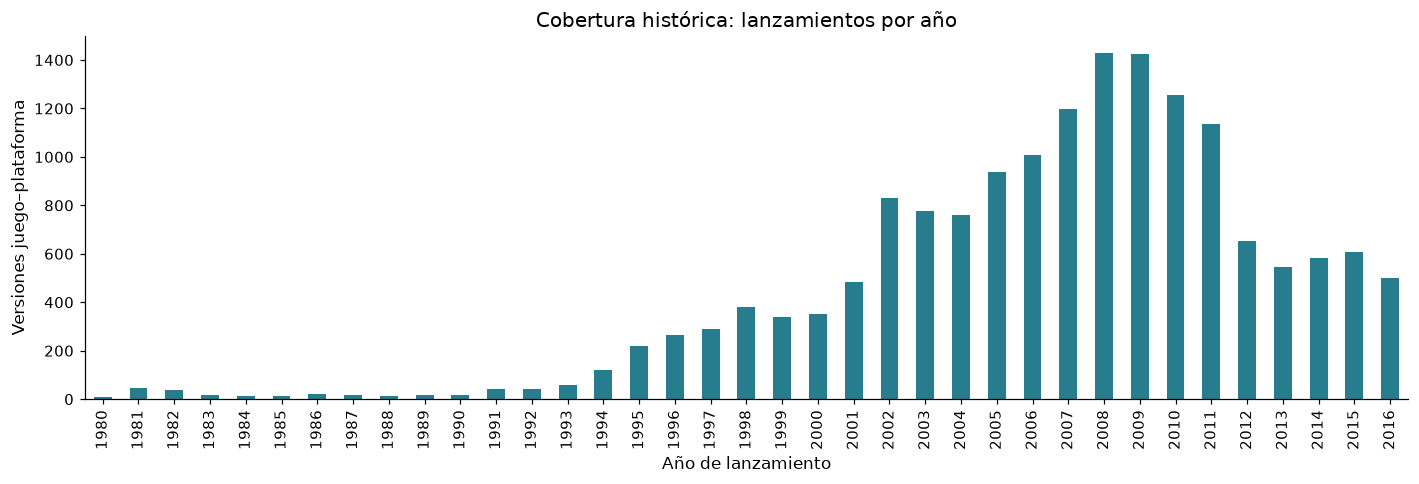

In [5]:
annual_releases = history.groupby('year_of_release').size()
display(annual_releases.to_frame('versiones_lanzadas'))
ax = annual_releases.plot(kind='bar', color='#277c8e', figsize=(13, 4.5))
ax.set(title='Cobertura histórica: lanzamientos por año', xlabel='Año de lanzamiento',
       ylabel='Versiones juego–plataforma')
plt.tight_layout()
plt.show()


El catálogo crece hasta alcanzar 1,427 registros en 2008 y 1,426 en 2009. Entre 2013 y 2016 hay 544, 581, 606 y 502, respectivamente. Los primeros años tienen pocos registros y pertenecen a generaciones muy distintas: aportan contexto histórico, pero no son igual de pertinentes para decidir una campaña de 2017.

La caída de registros en 2016 puede reflejar cobertura incompleta. El tamaño de cada período describe su cobertura, no garantiza representatividad ni demuestra por sí mismo una diferencia estadísticamente significativa.


### 3.2 Plataformas históricas y duración observada

Se eligen las seis plataformas con mayor venta histórica en la base con año conocido. Después se estima el intervalo entre primer y último año observado, y el tiempo desde el primero hasta la cohorte con mayores ventas. Son aproximaciones del ciclo del catálogo, no fechas oficiales de lanzamiento o retirada del hardware.


,ventas_totales
platform,
PS2,"1,233.5600"
X360,961.2400
PS3,931.3400
Wii,891.1800
DS,802.7800
PS,727.5800
PS4,314.1400
GBA,312.8800
PSP,289.5300


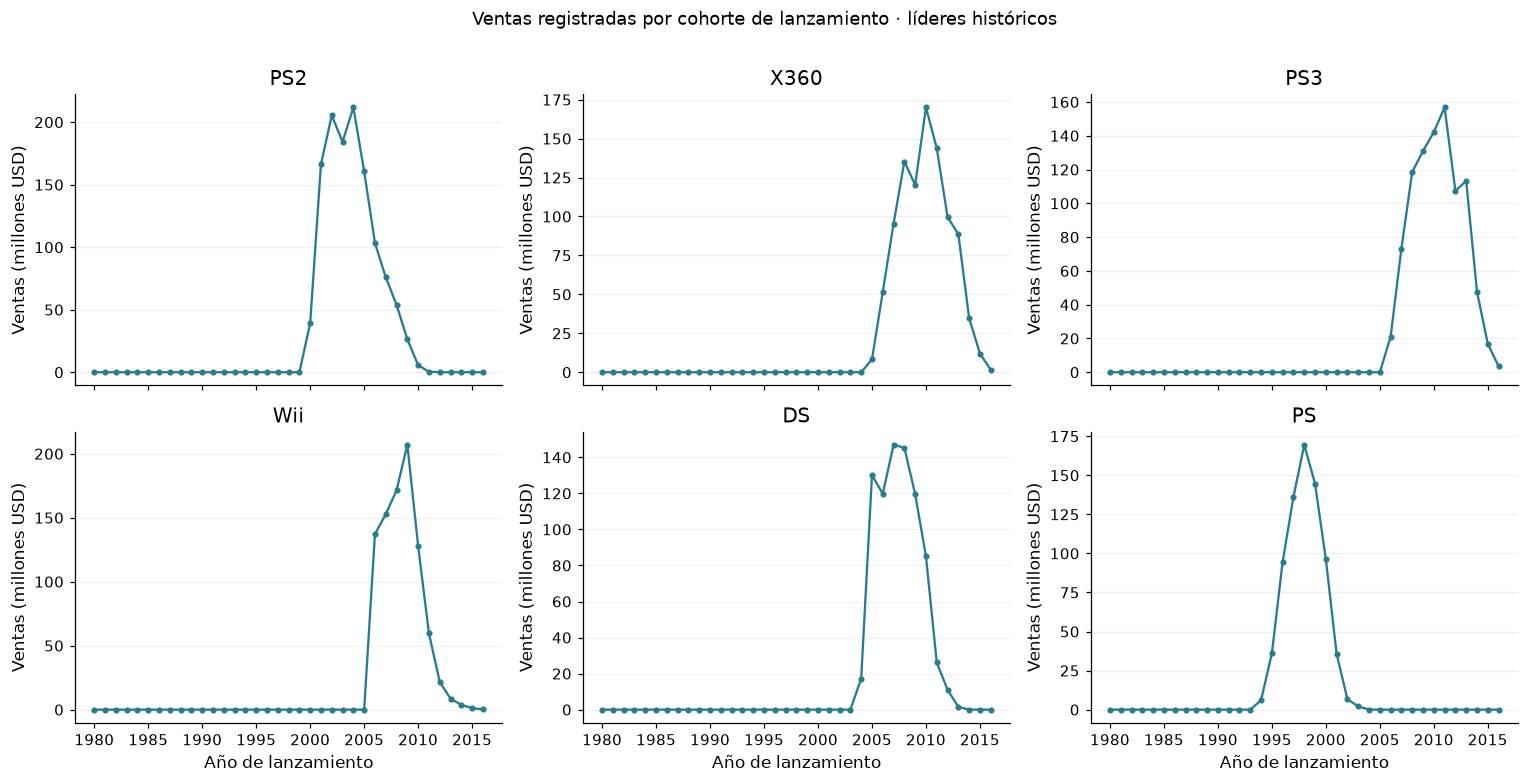

,primer_anio,ultimo_anio,ventas_totales,duracion_observada,anios_hasta_pico
platform,,,,,
NES,1983,1994,251.0500,12,2
GB,1988,2001,254.4300,14,1
SNES,1990,1999,200.0400,10,3
PS,1994,2003,727.5800,10,4
N64,1996,2002,218.0100,7,3
PS2,2000,2011,"1,233.5600",12,4
XB,2000,2008,251.5700,9,4
GBA,2000,2007,312.8800,8,4
GC,2001,2007,196.7300,7,1


Mediana del intervalo observado: 10.0 años
Mediana de años hasta el pico: 3.0


,primer_anio,ultimo_anio,ventas_totales,duracion_observada,anios_hasta_pico
platform,,,,,
PS,1994,2003,727.5800,10,4
PS2,2000,2011,"1,233.5600",12,4
PS3,2006,2016,931.3400,11,5
PS4,2013,2016,314.1400,4,2
XB,2000,2008,251.5700,9,4
X360,2005,2016,961.2400,12,5
XOne,2013,2016,159.3200,4,2


In [6]:
historical_sales = history.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
display(historical_sales.head(10).to_frame('ventas_totales'))
top_historical = historical_sales.head(6).index
platform_year = history.pivot_table(index='year_of_release', columns='platform',
                                   values='total_sales', aggfunc='sum', fill_value=0)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, platform in zip(axes.flat, top_historical):
    platform_year[platform].plot(ax=ax, marker='o', markersize=3, color='#277c8e')
    ax.set(title=platform, xlabel='Año de lanzamiento', ylabel='Ventas (millones USD)')
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Ventas registradas por cohorte de lanzamiento · líderes históricos', y=1.01)
plt.tight_layout()
plt.show()

lifecycle = history.groupby('platform').agg(
    primer_anio=('year_of_release', 'min'), ultimo_anio=('year_of_release', 'max'),
    ventas_totales=('total_sales', 'sum'))
lifecycle['duracion_observada'] = lifecycle['ultimo_anio'] - lifecycle['primer_anio'] + 1
peak_year = history.groupby(['platform', 'year_of_release'])['total_sales'].sum().reset_index()
peak_year = peak_year.loc[peak_year.groupby('platform')['total_sales'].idxmax()]
peak_year = peak_year.set_index('platform')['year_of_release']
lifecycle['anios_hasta_pico'] = peak_year - lifecycle['primer_anio']
# Plataformas sustanciales cuyo último lanzamiento observado es anterior a 2016.
completed_cycles = lifecycle[(lifecycle['ventas_totales'] >= 100) &
                            (lifecycle['ultimo_anio'] < 2016) &
                            (~lifecycle.index.isin(['DS', 'PC']))]
display(completed_cycles.sort_values('primer_anio'))
print('Mediana del intervalo observado:', completed_cycles['duracion_observada'].median(), 'años')
print('Mediana de años hasta el pico:', completed_cycles['anios_hasta_pico'].median())
display(lifecycle.loc[['PS', 'PS2', 'PS3', 'PS4', 'XB', 'X360', 'XOne']])


PS2 domina históricamente, seguida de X360, PS3, Wii, DS y PS. En plataformas de volumen sustancial cuyo catálogo observado termina antes de 2016, la mediana del intervalo es **10 años**, con duraciones de **7 a 14 años**. La mediana del tiempo entre la primera cohorte y la de mayores ventas es **3 años**. Estas cifras dependen de la selección y de la cobertura del archivo; no significan que cada consola deje de vender al cumplir diez años.

Las primeras cohortes observadas de PlayStation están en 1994, 2000, 2006 y 2013: relevos de 6–7 años. Para Xbox aparecen en 2000, 2005 y 2013: relevos de 5 y 8 años. Estas familias ilustran una sustitución aproximada cada **5–8 años**, con coexistencia de generaciones. PS y PS2 fueron líderes y no tienen nuevos lanzamientos registrados en 2016. La ausencia de nuevas filas no prueba que ya no se vendieran títulos antiguos.

### 3.3 Selección del período relevante

Se selecciona **2013–2016**: incluye las primeras cohortes de PS4 y Xbox One, permite observar su crecimiento y la reducción del catálogo de PS3/X360, y reúne cuatro años recientes. Usar toda la historia favorecería plataformas retiradas del catálogo. Usar solo 2016 reduciría demasiado la cobertura y dependería de un año posiblemente incompleto.

Desde esta sección, el análisis principal, perfiles y contrastes utilizan únicamente esa ventana. Se comprobará sensibilidad con 2014–2016 y 2013–2015. Esta selección se basa en pertinencia temporal, no en buscar un valor p determinado.


<div class="alert alert-block alert-success"> 
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Genial! Muy buen trabajo con las ventas por plataforma y los juegos lanzados por año. Además, se puede reconocer estos picos de diferentes plataformas de video juegos en las épocas datadas. Buen trabajo!
</div>

Registros del período: 2233 | títulos distintos: 1263


,count,sum
year_of_release,,
2013,544,361.2400
2014,581,331.5300
2015,606,267.9800
2016,502,129.9400


year_of_release,2013,2014,2015,2016,total,cambio_2014_2015_pct
platform,,,,,,
PS4,25.9900,100.0000,118.9000,69.2500,314.1400,18.9000
PS3,113.2500,47.7600,16.8200,3.6000,181.4300,-64.7822
XOne,18.9600,54.0700,60.1400,26.1500,159.3200,11.2262
3DS,56.5700,43.7600,27.7800,15.1400,143.2500,-36.5174
X360,88.5800,34.7400,11.9600,1.5200,136.8000,-65.5728
WiiU,21.6500,22.0300,16.3500,4.6000,64.6300,-25.7830
PC,12.3800,13.2800,8.5200,5.2500,39.4300,-35.8434
PSV,10.5900,11.9000,6.2500,4.2500,32.9900,-47.4790
Wii,8.5900,3.7500,1.1400,0.1800,13.6600,-69.6000


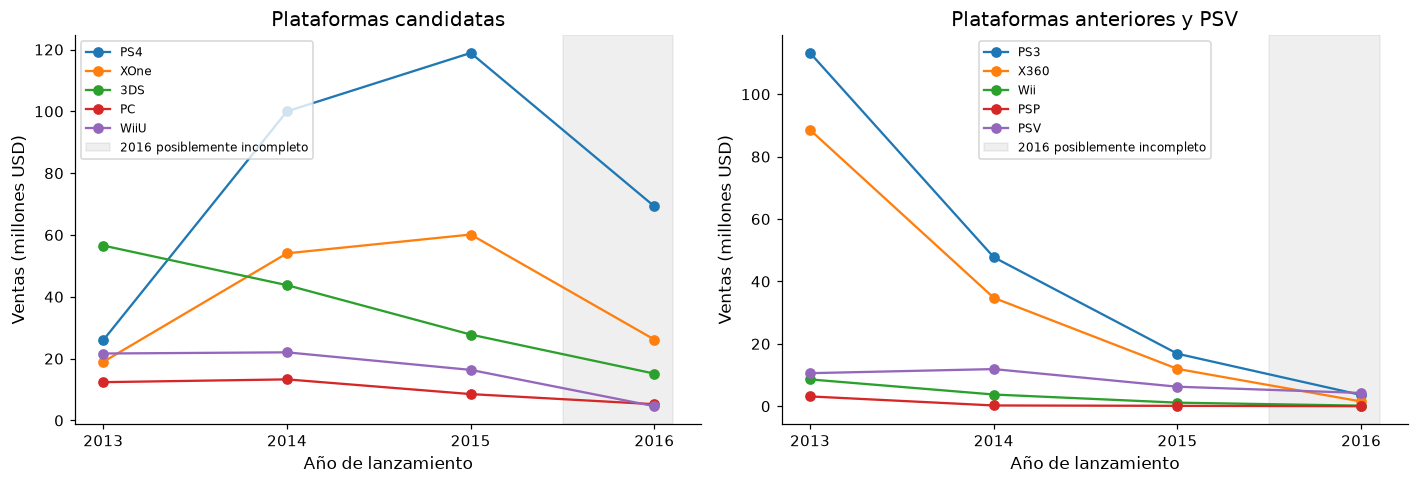

In [7]:
START_YEAR, END_YEAR = 2013, 2016
recent = history[history['year_of_release'].between(START_YEAR, END_YEAR)].copy()
print('Registros del período:', len(recent), '| títulos distintos:', recent['name'].nunique())
assert recent['year_of_release'].between(START_YEAR, END_YEAR).all()
display(recent.groupby('year_of_release')['total_sales'].agg(['count', 'sum']))

recent_year = recent.pivot_table(index='platform', columns='year_of_release',
                               values='total_sales', aggfunc='sum', fill_value=0)
recent_year['total'] = recent_year.sum(axis=1)
recent_year['cambio_2014_2015_pct'] = (recent_year[2015] / recent_year[2014].replace(0, np.nan) - 1) * 100
display(recent_year.sort_values('total', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for platform in ['PS4', 'XOne', '3DS', 'PC', 'WiiU']:
    axes[0].plot([2013, 2014, 2015, 2016], recent_year.loc[platform, [2013, 2014, 2015, 2016]].to_numpy(dtype=float), marker='o', label=platform)
for platform in ['PS3', 'X360', 'Wii', 'PSP', 'PSV']:
    axes[1].plot([2013, 2014, 2015, 2016], recent_year.loc[platform, [2013, 2014, 2015, 2016]].to_numpy(dtype=float), marker='o', label=platform)
for ax, title in zip(axes, ['Plataformas candidatas', 'Plataformas anteriores y PSV']):
    ax.set(title=title, xlabel='Año de lanzamiento', ylabel='Ventas (millones USD)', xticks=[2013,2014,2015,2016])
    ax.axvspan(2015.5, 2016.1, alpha=0.12, color='gray', label='2016 posiblemente incompleto')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### Interpretación de plataformas

PS4 lidera el período con **314.14 millones**, seguida de PS3 (181.43) y Xbox One (159.32). Sin embargo, el volumen acumulado de PS3 se concentra en 2013 y cae marcadamente después, al igual que X360. No conviene confundir un líder acumulado con una plataforma en expansión.

Entre cohortes de 2014 y 2015, PS4 aumenta de 100.00 a 118.90 y Xbox One de 54.07 a 60.14. Ambas son las candidatas principales para 2017. 3DS disminuye de 43.76 a 27.78, pero conserva importancia para Japón. PC puede servir para campañas selectivas; el volumen registrado no permite priorizarlo globalmente frente a PS4/XOne. WiiU también retrocede.

Todas muestran valores menores en 2016, pero no se anualiza ni se extrapola esa caída: no se conoce la fracción del año cubierta y los títulos más nuevos tienen menos tiempo para acumular ventas. No se afirma que alguna esté creciendo en 2016 basándose en estos datos incompletos.


### 3.4 Distribución de ventas por juego y plataforma

Los totales dependen del número de lanzamientos. Se comparan también media, mediana, cuartiles, desviación estándar y varianza muestrales (`ddof=1`). El segundo diagrama oculta los puntos extremos **solo en la visualización** para mostrar mejor las cajas; no se elimina ninguna venta del cálculo.


,juegos,ventas,media,mediana,varianza,desviacion_estandar,maximo,q25,q75
platform,,,,,,,,,
PS4,392,314.1400,0.8014,0.2000,2.5903,1.6095,14.6300,0.0600,0.7300
PS3,345,181.4300,0.5259,0.1500,2.1081,1.4519,21.0500,0.0400,0.5100
XOne,247,159.3200,0.6450,0.2200,1.0736,1.0361,7.3900,0.0600,0.6850
3DS,303,143.2500,0.4728,0.0900,1.9081,1.3813,14.6000,0.0400,0.2800
X360,186,136.8000,0.7355,0.2650,2.7665,1.6633,16.2700,0.0800,0.7950
WiiU,115,64.6300,0.5620,0.2000,1.0791,1.0388,7.0900,0.0600,0.5950
PC,189,39.4300,0.2086,0.0800,0.1241,0.3523,3.0500,0.0300,0.2300
PSV,358,32.9900,0.0922,0.0400,0.0237,0.1538,1.9600,0.0200,0.1100
Wii,23,13.6600,0.5939,0.1800,0.8380,0.9154,3.5800,0.0450,0.7550


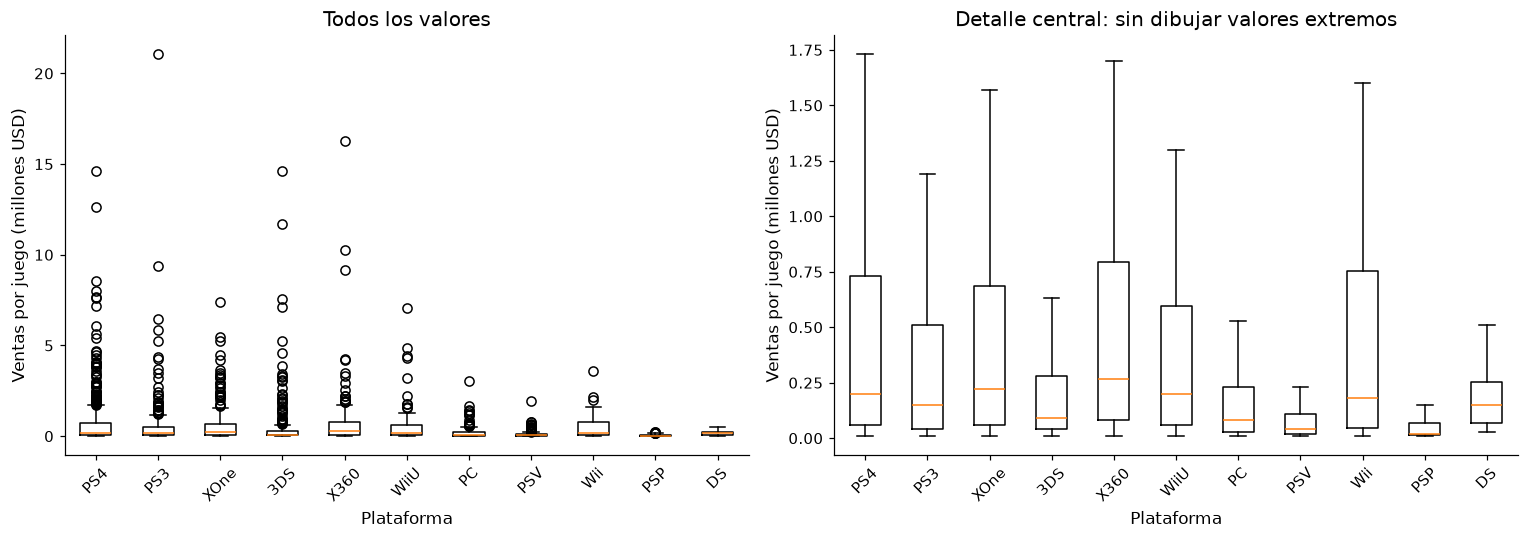

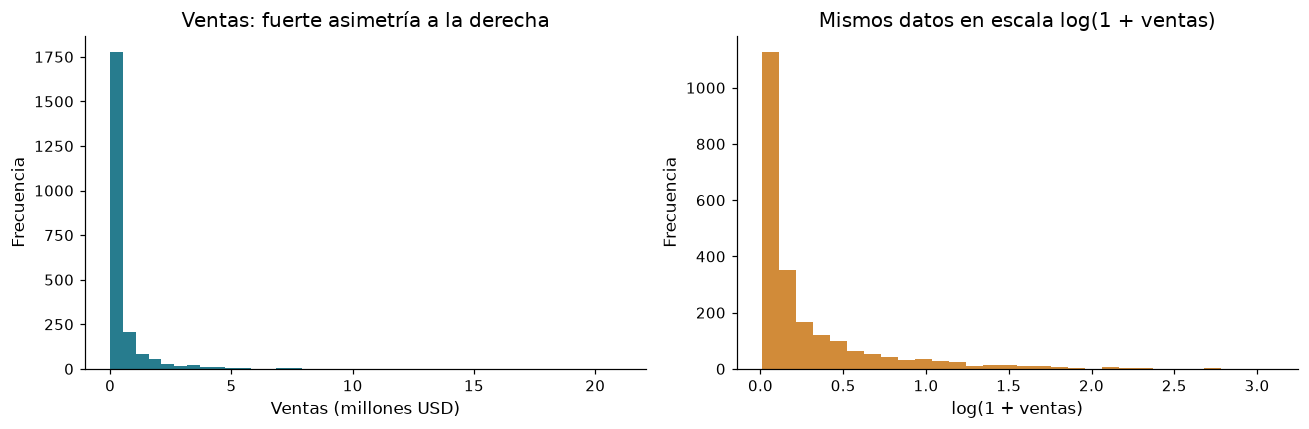

In [8]:
platform_summary = recent.groupby('platform')['total_sales'].agg(
    juegos='count', ventas='sum', media='mean', mediana='median',
    varianza='var', desviacion_estandar='std', maximo='max')
platform_summary['q25'] = recent.groupby('platform')['total_sales'].quantile(0.25)
platform_summary['q75'] = recent.groupby('platform')['total_sales'].quantile(0.75)
platform_summary = platform_summary.sort_values('ventas', ascending=False)
display(platform_summary)
order = platform_summary.index.tolist()
samples = [recent.loc[recent['platform'].eq(p), 'total_sales'] for p in order]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, show_outliers, title in zip(axes, [True, False], ['Todos los valores', 'Detalle central: sin dibujar valores extremos']):
    ax.boxplot(samples, showfliers=show_outliers)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(order, rotation=45)
    ax.set(title=title, xlabel='Plataforma', ylabel='Ventas por juego (millones USD)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
recent['total_sales'].plot.hist(bins=40, ax=axes[0], color='#277c8e')
np.log1p(recent['total_sales']).plot.hist(bins=30, ax=axes[1], color='#d18b39')
axes[0].set(title='Ventas: fuerte asimetría a la derecha', xlabel='Ventas (millones USD)', ylabel='Frecuencia')
axes[1].set(title='Mismos datos en escala log(1 + ventas)', xlabel='log(1 + ventas)', ylabel='Frecuencia')
plt.tight_layout()
plt.show()


Las medias exceden las medianas: pocos éxitos elevan el promedio. PS4 tiene media **0.801** y mediana **0.200**; Xbox One, **0.645** y **0.220**; PC, **0.209** y **0.080**. X360 conserva una mediana de 0.265 en los lanzamientos seleccionados, pero su reducción temporal desaconseja priorizarlo solo por esa cifra.

Hay diferencias descriptivas de nivel y dispersión, aunque las distribuciones se solapan. Un boxplot no demuestra «significación estadística». No se realiza aquí una batería de pruebas entre plataformas: la comparación es exploratoria y las pruebas formales solicitadas se reservan para las calificaciones. La varianza está en unidades cuadradas; la desviación estándar conserva las unidades de las ventas.


<div class="alert alert-block alert-success"> 
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Tu elección de rango temporal para el analisis es muy valida, en efecto, un periodo no mayor de 5 años es la mejor eleccion en este caso dada la alta variabilidad del comportamiento de las tecnologias emergentes en la ultima decada. 
Excelente trabajo con el analisis por plataforma para el periodo elegido. El grafico de cajas está correcto, bien hecho al poner limites en el eje Y que permitan observar mejor la distribucion por plataforma sin darle tanta importancia a los outliers.
</div>

### 3.5 Reseñas y ventas: PS4

Se elige PS4 por su liderazgo reciente. Para cada reseña se utilizan los pares completos puntuación–ventas; no se exige que ambas reseñas estén presentes a la vez. Se calcula la correlación de Pearson como resumen lineal.


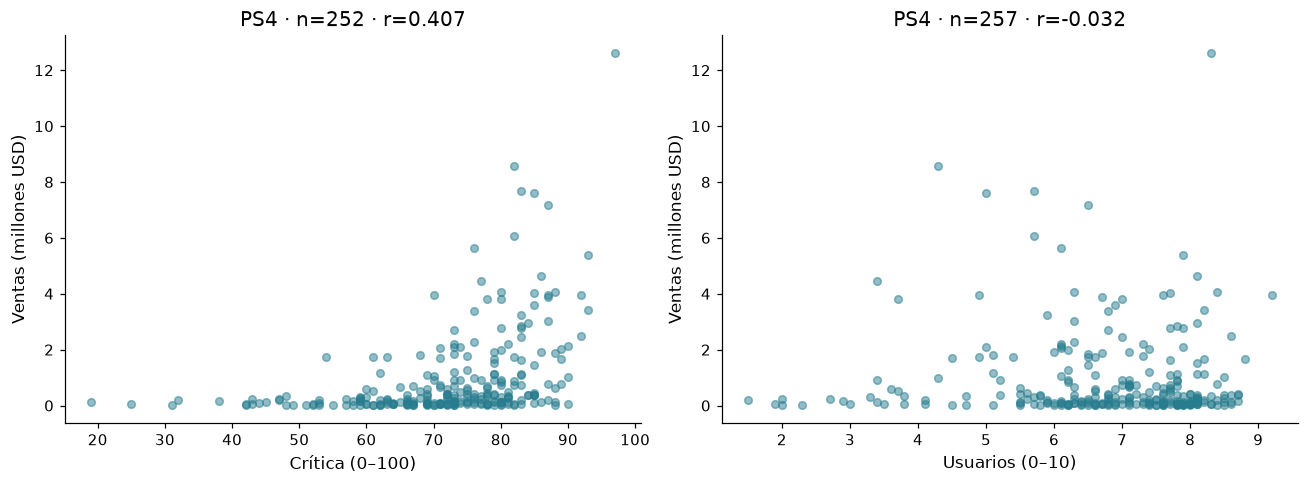

,reseña,n,pearson_r,sin_reseña_pct
0,critic_score,252,0.4066,35.7143
1,user_score,257,-0.0320,34.4388


,plataforma,reseña,n,r
0,PS4,critic_score,252,0.4066
1,PS4,user_score,257,-0.0320
2,XOne,critic_score,169,0.4170
3,XOne,user_score,182,-0.0689
4,PC,critic_score,149,0.1960
5,PC,user_score,155,-0.0938
6,3DS,critic_score,71,0.3571
7,3DS,user_score,80,0.2415
8,PS3,critic_score,121,0.3343
9,PS3,user_score,186,0.0024


In [9]:
ps4 = recent[recent['platform'].eq('PS4')]
correlations = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, score, label in zip(axes, ['critic_score','user_score'], ['Crítica (0–100)', 'Usuarios (0–10)']):
    observed = ps4.dropna(subset=[score, 'total_sales'])
    r = observed[score].corr(observed['total_sales'])
    correlations.append({'reseña': score, 'n': len(observed), 'pearson_r': r,
                         'sin_reseña_pct': 100 * ps4[score].isna().mean()})
    ax.scatter(observed[score], observed['total_sales'], alpha=0.5, s=25, color='#277c8e')
    ax.set(title=f'PS4 · n={len(observed)} · r={r:.3f}', xlabel=label, ylabel='Ventas (millones USD)')
plt.tight_layout()
plt.show()
display(pd.DataFrame(correlations))

comparison_correlations = []
for platform in ['PS4', 'XOne', 'PC', '3DS', 'PS3']:
    subset = recent[recent['platform'].eq(platform)]
    for score in ['critic_score', 'user_score']:
        observed = subset.dropna(subset=[score])
        comparison_correlations.append({'plataforma': platform, 'reseña': score,
                                        'n': len(observed), 'r': observed[score].corr(observed['total_sales'])})
display(pd.DataFrame(comparison_correlations))


En PS4, la correlación crítica–ventas es **r = 0.407** (252 pares), positiva moderada. La relación usuarios–ventas es prácticamente nula (**r = −0.032**, 257 pares). Xbox One presenta un patrón similar: r = 0.417 para crítica y −0.069 para usuarios. En PC la correlación con crítica es menor (0.196); no corresponde generalizar una relación idéntica a todas las plataformas.

No se demuestra que mejorar la reseña cause más ventas. Presupuesto, franquicia, promoción y tiempo desde el lanzamiento pueden influir en ambas variables. Además, los juegos sin reseñas pueden diferir sistemáticamente de los observados. Las puntuaciones son una señal complementaria, no un predictor suficiente ni una regla para descartar juegos.


<div class="alert alert-block alert-success"> 
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Excelente trabajo con el analisis de correlaciones de reseñas y ventas. Como mencionas para las diferentes plataformas abordadas, las reseñas de críticos representan una mayor influencia en las ventas, lo cual permite abrir pruebas posteriores para estudiar la causalidad entre ambas variables y con ello poder tomar acciones de negocio.

### 3.6 Los mismos juegos en otras plataformas

Comparar catálogos completos confunde plataforma y selección de títulos. Como control descriptivo, se alinean por nombre las versiones de PS4, Xbox One y PC. Se conservan solo títulos observados en ambos miembros de cada comparación. El nombre es una clave aproximada: no garantiza ediciones o fechas de disponibilidad equivalentes.


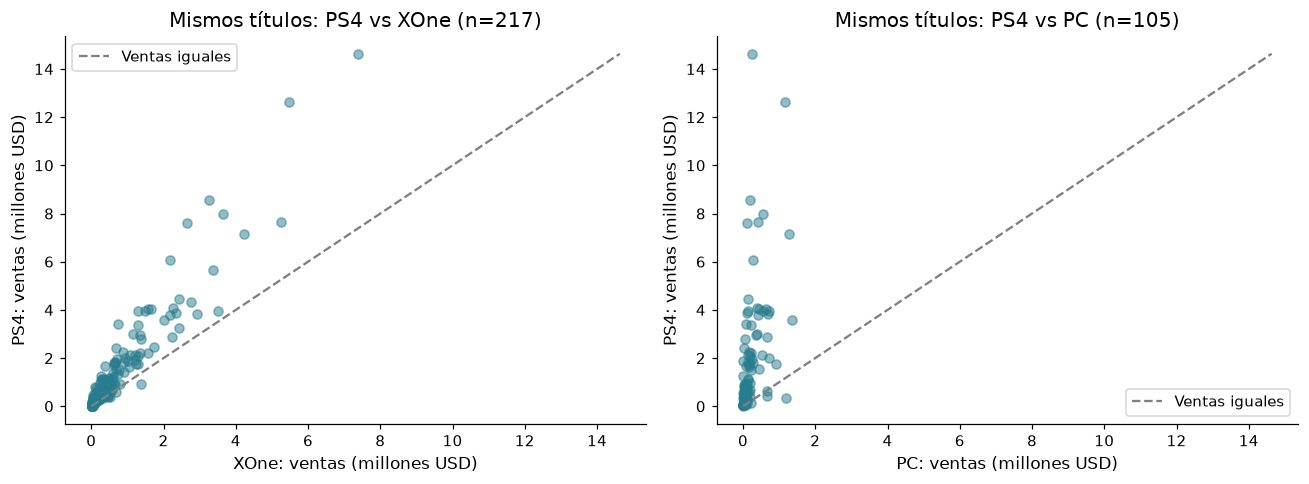

,comparacion,titulos_comunes,media_PS4,media_otro,mediana_PS4,mediana_otro,PS4_supera_otro_pct
0,PS4 vs XOne,217,1.1813,0.5961,0.4200,0.2100,93.0876
1,PS4 vs PC,105,1.8703,0.2145,0.7800,0.1000,94.2857


platform,PC,PS4,XOne
name,,,
Call of Duty: Black Ops 3,0.2600,14.6300,7.3900
Grand Theft Auto V,1.1700,12.6200,5.4700
FIFA 16,0.2000,8.5800,3.2500
Star Wars Battlefront (2015),0.5500,7.9800,3.6600
Call of Duty: Advanced Warfare,0.4100,7.6600,5.2600
FIFA 17,0.1200,7.6000,2.6500
Fallout 4,1.2800,7.1700,4.2200
FIFA 15,0.2900,6.0800,2.1800
Call of Duty: Infinite Warfare,0.1300,4.4700,2.4200


Títulos comunes a las tres plataformas: 97


platform,PC,PS4,XOne
mean,0.2282,2.0074,0.9813
median,0.1200,0.9200,0.5300


In [10]:
shared_sales = recent[recent['platform'].isin(['PS4','XOne','PC'])].pivot_table(
    index='name', columns='platform', values='total_sales', aggfunc='sum')
pair_summary = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, other in zip(axes, ['XOne', 'PC']):
    pair = shared_sales[['PS4', other]].dropna()
    pair_summary.append({'comparacion': 'PS4 vs ' + other, 'titulos_comunes': len(pair),
                         'media_PS4': pair['PS4'].mean(), 'media_otro': pair[other].mean(),
                         'mediana_PS4': pair['PS4'].median(), 'mediana_otro': pair[other].median(),
                         'PS4_supera_otro_pct': 100 * (pair['PS4'] > pair[other]).mean()})
    ax.scatter(pair[other], pair['PS4'], alpha=0.5, color='#277c8e')
    limit = pair.max().max()
    ax.plot([0,limit], [0,limit], '--', color='gray', label='Ventas iguales')
    ax.set(title=f'Mismos títulos: PS4 vs {other} (n={len(pair)})',
           xlabel=f'{other}: ventas (millones USD)', ylabel='PS4: ventas (millones USD)')
    ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(pair_summary))
common_all = shared_sales.dropna()
display(common_all.sort_values('PS4', ascending=False).head(10))
print('Títulos comunes a las tres plataformas:', len(common_all))
display(common_all.agg(['mean', 'median']))


Hay **217 títulos comunes PS4–Xbox One**: sus medianas son 0.42 y 0.21 millones. PS4 supera a Xbox One en el 93.1% de esos títulos. En los **105 títulos PS4–PC**, las medianas son 0.78 y 0.10. Entre las tres plataformas coinciden 97 títulos.

La ventaja de PS4 no depende únicamente de incluir exclusivos, aunque tampoco prueba un efecto causal de la plataforma. Fechas, base de usuarios, promociones y cobertura de ventas pueden diferir. Este subconjunto excluye exclusivos y juegos ausentes del catálogo: sus resultados no se extrapolan a todos los videojuegos.


### 3.7 Géneros: volumen y ventas por lanzamiento

El género con más ventas totales puede tener simplemente más juegos. Se comparan conteo, suma, media, mediana y dispersión; «más vendido» no equivale a «más rentable» sin costos.


,juegos,ventas,media,mediana,varianza,desviacion_estandar
genre,,,,,,
Action,766,321.8700,0.4202,0.1100,1.5723,1.2539
Shooter,187,232.9800,1.2459,0.4500,4.0566,2.0141
Sports,214,150.6500,0.7040,0.2400,1.4865,1.2192
Role-Playing,292,145.8900,0.4996,0.1250,1.8311,1.3532
Misc,155,62.8200,0.4053,0.1000,1.0160,1.0080
Platform,74,42.6300,0.5761,0.2250,0.6509,0.8068
Racing,85,39.8900,0.4693,0.1200,0.9295,0.9641
Fighting,80,35.3100,0.4414,0.1250,1.1002,1.0489
Adventure,245,23.6400,0.0965,0.0300,0.0468,0.2164


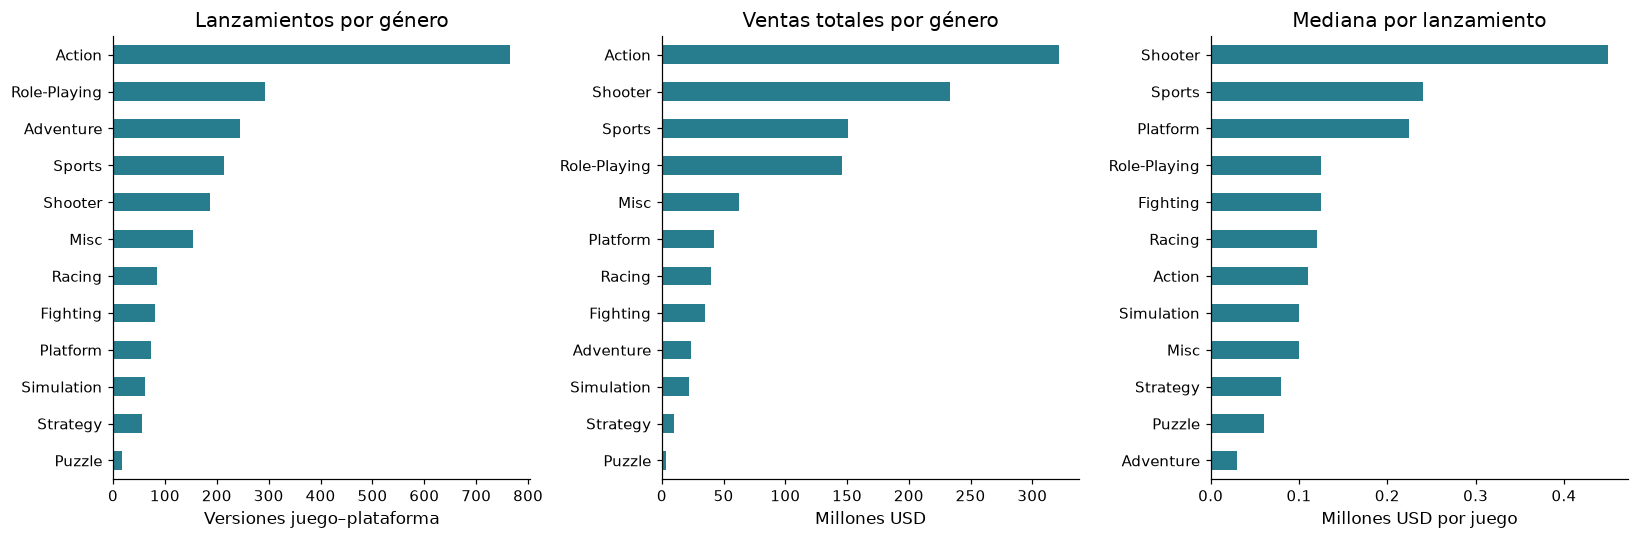

In [11]:
genre_summary = recent.groupby('genre')['total_sales'].agg(
    juegos='count', ventas='sum', media='mean', mediana='median', varianza='var', desviacion_estandar='std')
genre_summary = genre_summary.sort_values('ventas', ascending=False)
display(genre_summary)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, metric, title, xlabel in zip(axes, ['juegos','ventas','mediana'],
    ['Lanzamientos por género', 'Ventas totales por género', 'Mediana por lanzamiento'],
    ['Versiones juego–plataforma', 'Millones USD', 'Millones USD por juego']):
    genre_summary[metric].sort_values().plot.barh(ax=ax, color='#277c8e')
    ax.set(title=title, xlabel=xlabel, ylabel='')
plt.tight_layout()
plt.show()


**Action** lidera el total (321.87 millones) pero también el catálogo (766 registros); su mediana es 0.110. **Shooter** combina ventas elevadas (232.98) con una mediana mucho mayor (**0.450**) y media de 1.246, en 187 registros. **Sports** tiene mediana de 0.240 y **Platform** de 0.225.

Adventure tiene una mediana de 0.030 a pesar de sus 245 registros. Puzzle y Strategy tienen menor volumen global, pero eso no implica que ningún título de esos géneros pueda funcionar. Las diferencias regionales y la dispersión impiden generalizar el éxito a cada juego. Para una primera selección comercial, Shooter y Sports destacan por desempeño por lanzamiento; Action por tamaño total, con una selección más cuidadosa.


<div class="alert alert-block alert-success"> 
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Muy buen trabajo con la graficacion para el analisis de juegos multiplataforma, al igual que para las ventas por género. De forma ordenada has dado a entender las tendencias principales y también los nichos de mercado que se pueden estudiar o aprovechar en la toma de acciones de negocio. 

## 4. Perfil regional

Se construye un perfil del **mercado observado**, no de personas: no hay edades, género de compradores ni identificadores de usuarios. Las cuotas usan como denominador todas las ventas de la región en 2013–2016, no solo su top cinco. `Other_sales` se incluye en la venta global pero no se presenta como región NA/UE/JP.


Plataformas — Norteamérica


,ventas,cuota_pct
platform,,
PS4,108.7400,24.8429
XOne,93.1200,21.2744
X360,81.6600,18.6562
PS3,63.5000,14.5073
3DS,38.2000,8.7272


Cuota restante (%): 11.99
Plataformas — Europa


,ventas,cuota_pct
platform,,
PS4,141.0900,35.9712
PS3,67.8100,17.2883
XOne,51.5900,13.1530
X360,42.5200,10.8406
3DS,30.9600,7.8933


Cuota restante (%): 14.85
Plataformas — Japón


,ventas,cuota_pct
platform,,
3DS,67.8100,48.1674
PS3,23.3500,16.5862
PSV,18.5900,13.2050
PS4,15.9600,11.3368
WiiU,10.8800,7.7284


Cuota restante (%): 2.98


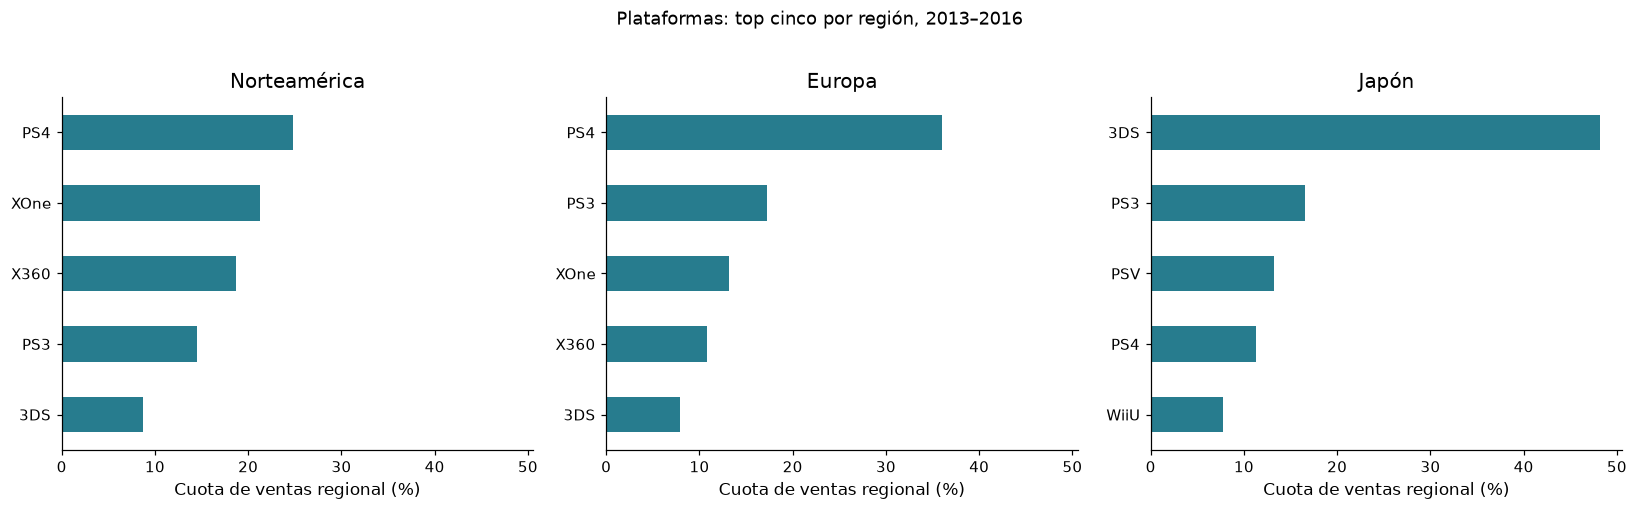

Géneros — Norteamérica


,ventas,cuota_pct
genre,,
Action,126.0500,28.7976
Shooter,109.7400,25.0714
Sports,65.2700,14.9117
Role-Playing,46.4000,10.6006
Misc,27.4900,6.2804


Cuota restante (%): 14.34
Géneros — Europa


,ventas,cuota_pct
genre,,
Action,118.1300,30.1175
Shooter,87.8600,22.4001
Sports,60.5200,15.4297
Role-Playing,36.9700,9.4256
Racing,20.1900,5.1475


Cuota restante (%): 17.48
Géneros — Japón


,ventas,cuota_pct
genre,,
Role-Playing,51.0400,36.2551
Action,40.4900,28.7612
Misc,9.2000,6.5350
Fighting,7.6500,5.4340
Shooter,6.6100,4.6953


Cuota restante (%): 18.32


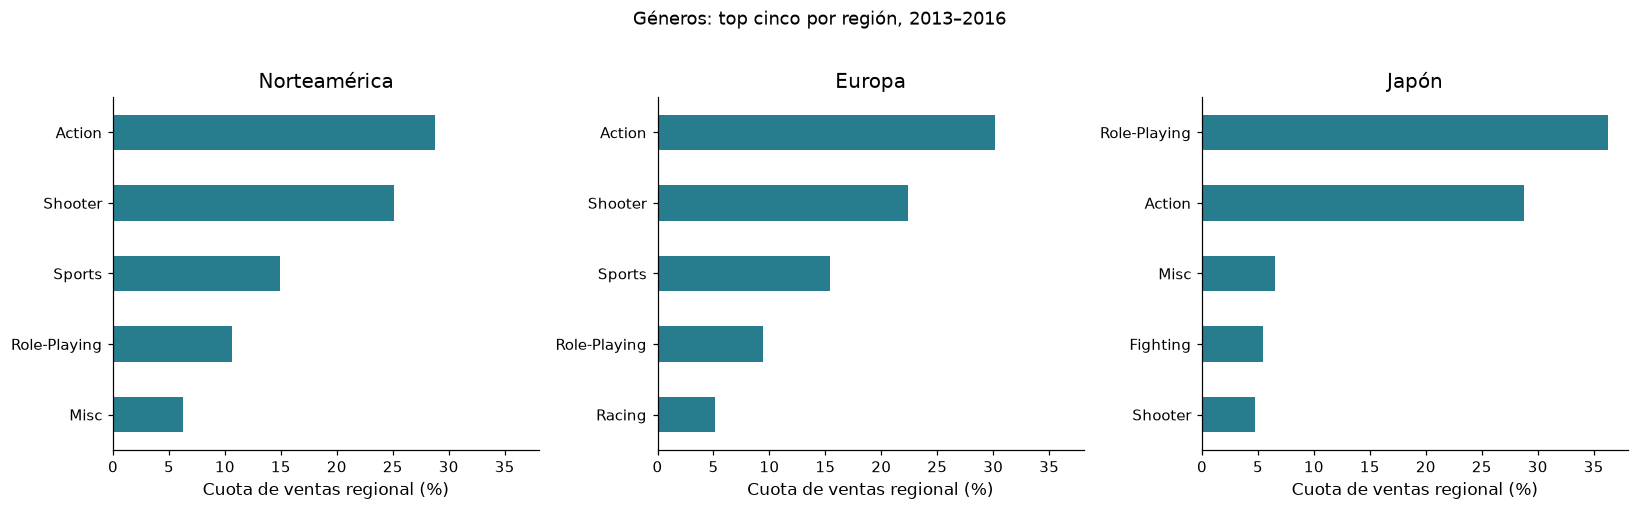

In [12]:
regions = {'na_sales': 'Norteamérica', 'eu_sales': 'Europa', 'jp_sales': 'Japón'}
regional_top = {}
for category, title in [('platform', 'Plataformas'), ('genre', 'Géneros')]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
    for ax, (region, label) in zip(axes, regions.items()):
        ranked = recent.groupby(category)[region].sum().sort_values(ascending=False)
        top = ranked.head(5).to_frame('ventas')
        top['cuota_pct'] = top['ventas'] / recent[region].sum() * 100
        regional_top[(category, region)] = top
        print(title, '—', label)
        display(top)
        print('Cuota restante (%):', round(100 - top['cuota_pct'].sum(), 2))
        top['cuota_pct'].sort_values().plot.barh(ax=ax, color='#277c8e')
        ax.set(title=label, xlabel='Cuota de ventas regional (%)', ylabel='')
    fig.suptitle(f'{title}: top cinco por región, 2013–2016', y=1.02)
    plt.tight_layout()
    plt.show()


### Interpretación de plataformas y géneros

| Región | Plataformas y cuotas principales | Géneros y cuotas principales |
|---|---|---|
| Norteamérica | PS4 24.8%, XOne 21.3%, X360 18.7%, PS3 14.5%, 3DS 8.7% | Action 28.8%, Shooter 25.1%, Sports 14.9%, Role-Playing 10.6%, Misc 6.3% |
| Europa | PS4 36.0%, PS3 17.3%, XOne 13.2%, X360 10.8%, 3DS 7.9% | Action 30.1%, Shooter 22.4%, Sports 15.4%, Role-Playing 9.4%, Racing 5.1% |
| Japón | 3DS 48.2%, PS3 16.6%, PSV 13.2%, PS4 11.3%, WiiU 7.7% | Role-Playing 36.3%, Action 28.8%, Misc 6.5%, Fighting 5.4%, Shooter 4.7% |

Norteamérica y Europa comparten Action, Shooter y Sports, pero Europa concentra una cuota mayor en PS4 y Norteamérica muestra más peso relativo de Xbox. Japón se diferencia por 3DS, PSV y Role-Playing. Los líderes históricos del período no deben trasladarse mecánicamente al presupuesto de 2017: también importa la evolución reciente.

### 4.1 Clasificación ESRB y ventas

Se incluye «Sin dato ESRB» en el denominador. M indica Mature, T Teen, E Everyone y E10+ Everyone 10+. Las etiquetas describen contenido, no la edad observada de los compradores. Se comparan suma y venta media/mediana por juego para no atribuir todo el volumen al rating.


,na_sales,eu_sales,jp_sales
rating_group,,,
E,79.0500,83.3600,15.1400
E10+,54.2400,42.6900,5.8900
M,165.2100,145.3200,14.1100
Sin dato ESRB,89.4200,78.9100,85.0500
T,49.7900,41.9500,20.5900


,na_sales,eu_sales,jp_sales
rating_group,,,
E,18.0599,21.2528,10.7544
E10+,12.3918,10.8839,4.1838
M,37.7442,37.0497,10.0227
Sin dato ESRB,20.4291,20.1183,60.4134
T,11.3751,10.6953,14.6257


na_sales               eu_sales               jp_sales              
                 count   mean median    count   mean median    count   mean median
rating_group                                                                      
E                  302 0.2618 0.0500      302 0.2760 0.0550      302 0.0501 0.0000
E10+               252 0.2152 0.1200      252 0.1694 0.1000      252 0.0234 0.0000
M                  369 0.4477 0.1400      369 0.3938 0.1300      369 0.0382 0.0000
Sin dato ESRB      977 0.0915 0.0000      977 0.0808 0.0000      977 0.0871 0.0200
T                  333 0.1495 0.0400      333 0.1260 0.0400      333 0.0618 0.0100

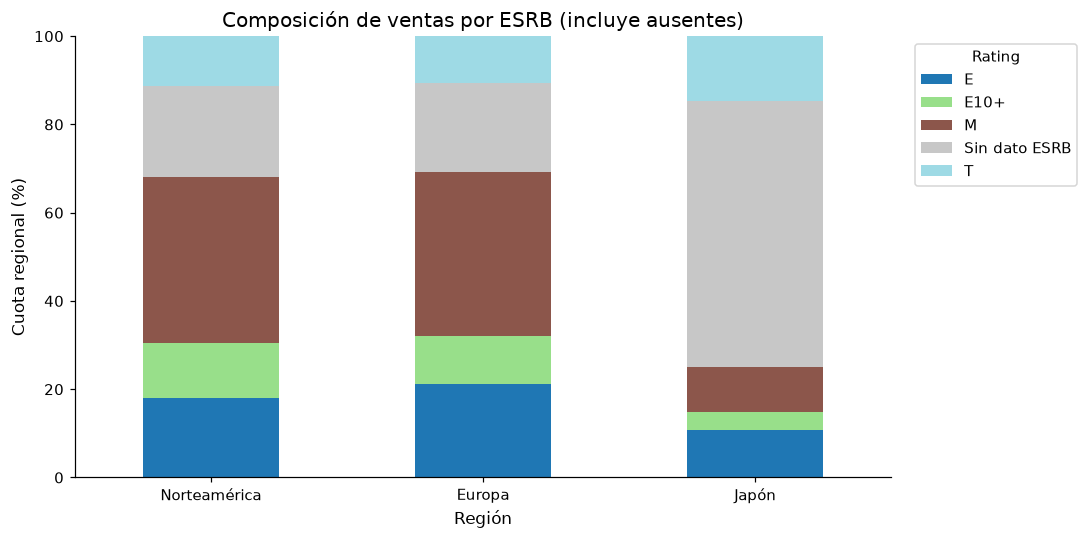

In [13]:
rating_sales = recent.groupby('rating_group')[list(regions)].sum()
rating_shares = rating_sales.div(recent[list(regions)].sum(), axis='columns') * 100
display(rating_sales)
display(rating_shares)
rating_detail = recent.groupby('rating_group')[list(regions)].agg(['count','mean','median'])
display(rating_detail)
ax = rating_shares.rename(columns=regions).T.plot.bar(stacked=True, figsize=(10, 5), colormap='tab20')
ax.set(title='Composición de ventas por ESRB (incluye ausentes)', xlabel='Región', ylabel='Cuota regional (%)', ylim=(0,100))
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Rating', bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()


M concentra las mayores ventas con rating conocido en Norteamérica (165.21 millones) y Europa (145.32). En Japón domina **Sin dato ESRB** (85.05 millones); entre ratings conocidos, T es el mayor (20.59). La ausencia de clasificación ocupa una parte importante del mercado japonés y no debe eliminarse ni interpretarse como una categoría de edad.

Existen diferencias descriptivas entre categorías, pero no se demuestra que ESRB cause las ventas. El catálogo, género, plataforma y cobertura regional pueden explicar parte de la asociación. Para las campañas se debe comprobar la clasificación real de cada producto y evitar inferir la edad del público a partir de estas tablas.


<div class="alert alert-block alert-success"> 
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Los perfiles de usuario que presentas están muy completos y el analisis frente a los resultados también es muy bueno. Como mencionas, norteamerica y Europa tienen caracteristicas compartidas, siendo Japon una region diferencial para tener en cuenta en la toma de decisiones. 

## 5. Pruebas de hipótesis
### Diseño y criterio de decisión

Se fija **α = 0.05** para cada contraste bilateral, antes de interpretar los resultados. Se usa la prueba t de Welch (`ttest_ind(..., equal_var=False)`), que compara medias sin asumir varianzas iguales. Se utilizan únicamente calificaciones numéricas observadas de 2013–2016. No se ponderan por ventas: la pregunta es la calificación media de las versiones de juegos, no la experiencia media de compradores.

Las puntuaciones están acotadas, pueden ser asimétricas y no constituyen una muestra aleatoria de todos los juegos del mercado. Los tamaños muestrales permiten una aproximación para las medias, pero no eliminan sesgo de selección ni dependencia. Un título puede estar en varias plataformas y compartir franquicia con otros; por eso el contraste por filas se trata como exploratorio y se añaden comprobaciones por título.

**Decisión:** si p < α se rechaza H0. Si p ≥ α no se rechaza; esto no prueba igualdad o equivalencia. El valor p no es la probabilidad de que H0 sea verdadera. Se reporta además diferencia de medias, varianza y desviación estándar.

### 5.1 Xbox One y PC

- **H0:** μ_XOne = μ_PC.
- **H1:** μ_XOne ≠ μ_PC.

La afirmación «son las mismas» se coloca en la hipótesis nula y se busca evidencia de una diferencia en cualquier dirección.

### 5.2 Action y Sports

- **H0:** μ_Action = μ_Sports.
- **H1:** μ_Action ≠ μ_Sports.

«Son diferentes» corresponde a la hipótesis alternativa bilateral, no a la nula.


,comparacion,n_A,n_B,media_A,media_B,var_A,var_B,sd_A,sd_B,diferencia_A_B,t,decision
0,XOne vs PC,182,155,6.5214,6.2697,1.9070,3.0359,1.3809,1.7424,0.2518,1.4519,No rechazar H0
1,Action vs Sports,389,160,6.8375,5.2381,1.7694,3.1806,1.3302,1.7834,1.5994,10.2334,Rechazar H0


XOne vs PC | p = 0.1475959401 | No rechazar H0
Action vs Sports | p = 1.44600397e-20 | Rechazar H0
Bonferroni para dos contrastes, como comprobación: 0.025
Rechazo con umbral 0.025: [False, True]


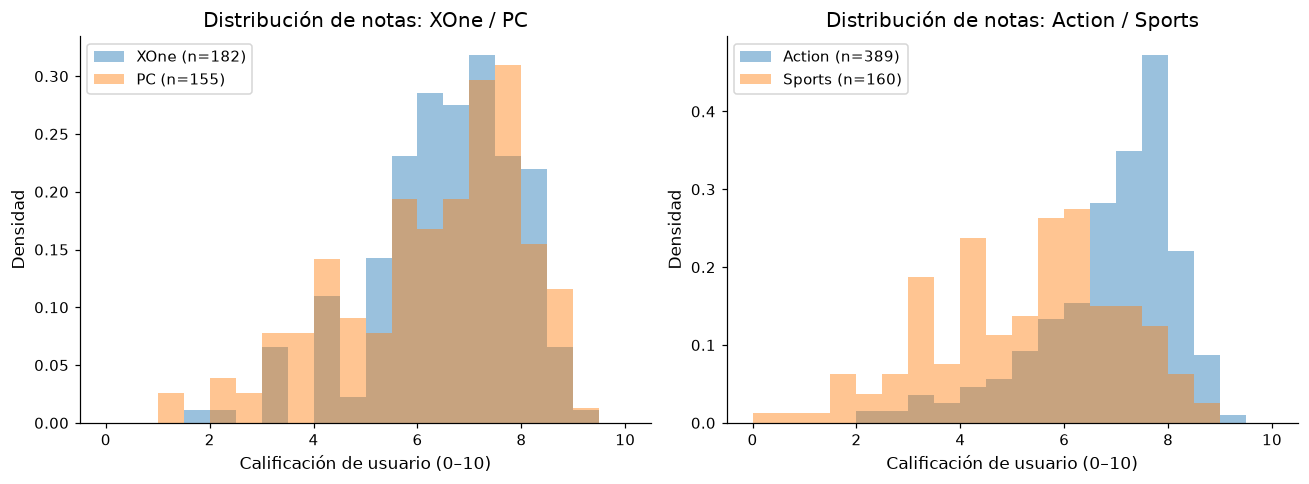

In [14]:
ALPHA = 0.05

def compare_scores(data, column, group_a, group_b):
    """Comparar medias observadas con Welch, conservando tamaños y dispersión."""
    a = data.loc[data[column].eq(group_a), 'user_score'].dropna()
    b = data.loc[data[column].eq(group_b), 'user_score'].dropna()
    result = st.ttest_ind(a, b, equal_var=False)
    return {'comparacion': group_a + ' vs ' + group_b,
            'n_A': len(a), 'n_B': len(b), 'media_A': a.mean(), 'media_B': b.mean(),
            'var_A': a.var(ddof=1), 'var_B': b.var(ddof=1),
            'sd_A': a.std(ddof=1), 'sd_B': b.std(ddof=1),
            'diferencia_A_B': a.mean() - b.mean(), 't': result.statistic,
            'p': result.pvalue, 'decision': 'Rechazar H0' if result.pvalue < ALPHA else 'No rechazar H0'}

h1 = compare_scores(recent, 'platform', 'XOne', 'PC')
h2 = compare_scores(recent, 'genre', 'Action', 'Sports')
tests = pd.DataFrame([h1, h2])
display(tests.drop(columns='p'))
for row in [h1, h2]:
    print(row['comparacion'], '| p =', f"{row['p']:.10g}", '|', row['decision'])
print('Bonferroni para dos contrastes, como comprobación:', ALPHA / 2)
print('Rechazo con umbral 0.025:', (tests['p'] < ALPHA / 2).tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column, names in zip(axes, ['platform', 'genre'], [('XOne','PC'), ('Action','Sports')]):
    for name in names:
        values = recent.loc[recent[column].eq(name), 'user_score'].dropna()
        ax.hist(values, bins=np.arange(0, 10.5, 0.5), alpha=0.45, density=True, label=f'{name} (n={len(values)})')
    ax.set(title='Distribución de notas: ' + ' / '.join(names), xlabel='Calificación de usuario (0–10)', ylabel='Densidad')
    ax.legend()
plt.tight_layout()
plt.show()


### Resultados de los contrastes principales

1. **Xbox One frente a PC:** 182 y 155 notas observadas, con medias de **6.521** y **6.270**. La diferencia es de **0.252 puntos** y p ≈ **0.1476**. No se rechaza H0 al 5%. No hay evidencia suficiente de diferencia entre las medias de estos catálogos bajo este análisis; **no se demuestra igualdad**.
2. **Action frente a Sports:** 389 y 160 notas, con medias de **6.838** y **5.238**. La diferencia es de **1.599 puntos** y p ≈ **1.446 × 10⁻²⁰**. Se rechaza H0: las medias observadas son diferentes, con una calificación mayor en Action. Esto no implica mayores ventas de cada juego de Action ni un efecto causal del género.

Aplicar un umbral conservador de 0.025 por dos comparaciones no cambia las decisiones principales. No se presenta ese ajuste como corrección de todos los análisis exploratorios del notebook.


### 5.3 Sensibilidad a la ventana temporal y a títulos repetidos

Se repiten las pruebas con ventanas alternativas sin modificar el análisis principal. Además, para Action/Sports se promedia la nota de cada título entre plataformas, de modo que cada nombre aporte una sola observación. Esto cambia el estimando a «media entre títulos», y evita dar más peso a juegos multiplataforma.

Para Xbox One/PC se distinguen dos comprobaciones: catálogos sin títulos compartidos (Welch) y títulos disponibles en ambas plataformas (t emparejada). Esta última prueba responde a una pregunta diferente: cómo varía la nota **del mismo título** entre plataformas. No sustituye la comparación de catálogos.


In [15]:
sensitivity = []
for start, end in [(2013,2016), (2014,2016), (2013,2015)]:
    window = history[history['year_of_release'].between(start, end)]
    for column, a, b in [('platform','XOne','PC'), ('genre','Action','Sports')]:
        row = compare_scores(window, column, a, b)
        sensitivity.append({'periodo': f'{start}–{end}', 'comparacion': row['comparacion'],
                            'n_A': row['n_A'], 'n_B': row['n_B'],
                            'diferencia': row['diferencia_A_B'], 'p': row['p'], 'decision': row['decision']})
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity.assign(p=sensitivity['p'].map(lambda p: f'{p:.6g}')))

action_sports = recent[recent['genre'].isin(['Action','Sports'])]
ambiguous_titles = action_sports.groupby('name')['genre'].nunique()
ambiguous_titles = ambiguous_titles[ambiguous_titles > 1].index
print('Títulos con ambos géneros, excluidos solo del control por título:', len(ambiguous_titles))
title_scores = (action_sports[~action_sports['name'].isin(ambiguous_titles)]
                .groupby(['name','genre'], as_index=False)['user_score'].mean())
title_test = compare_scores(title_scores, 'genre', 'Action', 'Sports')
print('Control de géneros por título:')
display(pd.DataFrame([title_test]).assign(p=lambda df: df['p'].map(lambda p: f'{p:.6g}')))

two_platforms = recent[recent['platform'].isin(['XOne','PC'])]
shared_names = two_platforms.groupby('name')['platform'].nunique()
shared_names = shared_names[shared_names == 2].index
exclusive = two_platforms[~two_platforms['name'].isin(shared_names)]
print('Control de catálogos sin títulos compartidos:')
exclusive_test = compare_scores(exclusive, 'platform', 'XOne', 'PC')
display(pd.DataFrame([exclusive_test]).assign(p=lambda df: df['p'].map(lambda p: f'{p:.6g}')))

paired_scores = two_platforms.pivot_table(index='name', columns='platform', values='user_score', aggfunc='mean').dropna()
paired_test = st.ttest_rel(paired_scores['XOne'], paired_scores['PC'])
print('Títulos emparejados con ambas notas:', len(paired_scores))
print('Diferencia media XOne–PC:', (paired_scores['XOne'] - paired_scores['PC']).mean())
print('p emparejada:', paired_test.pvalue)


,periodo,comparacion,n_A,n_B,diferencia,p,decision
0,2013–2016,XOne vs PC,182,155,0.2518,0.147596,No rechazar H0
1,2013–2016,Action vs Sports,389,160,1.5994,1.446e-20,Rechazar H0
2,2014–2016,XOne vs PC,165,122,0.2962,0.116014,No rechazar H0
3,2014–2016,Action vs Sports,297,127,1.5354,1.18256e-14,Rechazar H0
4,2013–2015,XOne vs PC,116,110,0.2194,0.286704,No rechazar H0
5,2013–2015,Action vs Sports,304,123,1.7134,3.50767e-19,Rechazar H0


Títulos con ambos géneros, excluidos solo del control por título: 0
Control de géneros por título:


,comparacion,n_A,n_B,media_A,media_B,var_A,var_B,sd_A,sd_B,diferencia_A_B,t,p,decision
0,Action vs Sports,169,57,6.8788,5.4543,1.7440,2.2148,1.3206,1.4882,1.4245,6.4236,6.67554e-09,Rechazar H0


Control de catálogos sin títulos compartidos:


,comparacion,n_A,n_B,media_A,media_B,var_A,var_B,sd_A,sd_B,diferencia_A_B,t,p,decision
0,XOne vs PC,102,71,6.3951,6.3338,2.1320,3.0186,1.4601,1.7374,0.0613,0.2434,0.808067,No rechazar H0


Títulos emparejados con ambas notas: 78
Diferencia media XOne–PC: 0.5717948717948718
p emparejada: 7.377992474860873e-06


<div class="alert alert-block alert-success"> 
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Hiciste un excelente trabajo con las pruebas de hipótesis. Tu eleccion de los tipos de prueba y los niveles de significancia es muy acertada. Además, las justificaciones que proporcionas para interpretar los resultados le dan un completo desarrollo al trabajo. Excelente

Las ventanas alternativas mantienen las decisiones principales: no rechazar igualdad entre catálogos Xbox One/PC y rechazar igualdad Action/Sports. Al promediar por título, la diferencia Action/Sports permanece (p ≈ 6.68 × 10⁻⁹); al excluir títulos compartidos, Xbox One/PC no muestra evidencia suficiente de diferencia (p ≈ 0.8081). El análisis emparejado de **78 títulos** sí encuentra una diferencia entre plataformas (p ≈ 7.38 × 10⁻⁶). No es una contradicción: compara el mismo catálogo compartido, mientras que Welch compara la mezcla completa de títulos de cada plataforma.

Esto refuerza la necesidad de evitar la conclusión absoluta «Xbox One y PC son iguales». También persisten dependencias entre franquicias y sesgo por notas ausentes; los contrastes son evidencia exploratoria condicionada al archivo, no una demostración universal.

## 6. Conclusión general

### Recomendaciones para la campaña de 2017

1. **Priorizar PS4 a escala global y en Europa.** Lidera las ventas de lanzamientos de 2013–2016, creció entre las cohortes de 2014 y 2015 y mantiene ventaja descriptiva al comparar los mismos títulos con otras plataformas.
2. **Considerar Xbox One como segunda prioridad, especialmente en Norteamérica.** Su cuota regional es 21.3%, frente a 13.2% en Europa. Evitar destinar presupuesto por inercia a PS3 o X360, cuyos nuevos catálogos se reducen.
3. **Diseñar una estrategia diferenciada para Japón.** 3DS concentra 48.2% de las ventas y Role-Playing 36.3%. Conservar una selección de títulos 3DS/RPG y evaluar PS4 sin asumir que el patrón occidental se replica. La reducción de las cohortes de 3DS aconseja seguimiento, no expansión indiscriminada.
4. **Combinar volumen y desempeño por juego.** Shooter y Sports destacan por medianas; Action por volumen total, aunque tiene muchos lanzamientos de bajo desempeño. No elegir un género solo por su suma de ventas.
5. **Usar crítica profesional como señal complementaria.** En PS4/XOne la asociación positiva con ventas es moderada. La nota de usuarios no muestra una asociación lineal clara en esas plataformas. Ninguna reseña garantiza éxito.
6. **Adaptar la comunicación al rating real y la región.** M concentra mayores ventas conocidas en NA/UE. En Japón, la gran proporción sin dato ESRB impide atribuir preferencias de edad. Verificar cada clasificación antes de segmentar una campaña.

### Respuesta a las hipótesis

- Xbox One/PC: p = 0.1476 en la comparación principal; no se rechaza igualdad de medias. La comparación emparejada de títulos revela que el resultado depende del catálogo seleccionado.
- Action/Sports: p ≈ 1.446 × 10⁻²⁰; existe evidencia de diferencia entre medias observadas, mayor en Action.

### Limitaciones y próximos datos necesarios

- 2016 puede estar incompleto; no se proyecta su total a un año completo.
- Las ventas están asociadas con lanzamientos, no con transacciones por año. Diferente antigüedad implica diferente tiempo de exposición comercial.
- Las reseñas y ESRB faltantes pueden introducir sesgos; no se sustituyeron por valores inventados.
- No hay costos, márgenes, stock, precios ni resultados de publicidad. No se estima ROI ni se reparte un presupuesto numérico sin esa información.
- No se dispone de ventas mensuales, cobertura de canales ni población compradora. Las cuotas pertenecen a este dataset, no necesariamente a todo el mercado.
- No se incluyen datos externos posteriores a 2016, ni se anticipa el desempeño de plataformas o juegos nuevos no observados.

**Síntesis:** para 2017, Ice debería concentrar la selección inicial en PS4 y Xbox One en mercados occidentales, con juegos Shooter/Sports y una selección de Action; para Japón, diferenciarse con 3DS y Role-Playing. Son prioridades comerciales basadas en patrones observados, no garantías de éxito ni beneficios. Antes de comprometer presupuesto, conviene completar 2016 y añadir margen, disponibilidad y métricas de campañas.

### Fuentes y trazabilidad

- Dataset y descripción: enlace del enunciado en la introducción. Todos los resultados numéricos se calculan en este notebook.
- [SciPy: prueba t independiente y opción Welch](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html).
- [SciPy: prueba t para muestras relacionadas](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html).

La documentación técnica se utiliza para verificar las funciones, no para incorporar resultados de mercado posteriores al escenario del proyecto.


In [16]:
# Verificaciones finales reproducibles: consistencia de filas, período y resultados.
assert len(raw) == len(games)
assert recent[key_columns].duplicated().sum() == 0
assert recent['total_sales'].notna().all()
assert recent['year_of_release'].max() <= END_YEAR
assert np.isfinite(tests['p']).all() and tests['p'].between(0, 1).all()
for region in regions:
    assert np.isclose(recent.groupby('rating_group')[region].sum().sum(), recent[region].sum())
print('Comprobaciones superadas: datos originales conservados, período correcto y resultados finitos.')
print('El análisis queda pendiente de revisión académica; no se presupone su aprobación.')


Comprobaciones superadas: datos originales conservados, período correcto y resultados finitos.
El análisis queda pendiente de revisión académica; no se presupone su aprobación.


<div class="alert alert-block alert-success"> 
<b>Comentario de la revisora Iteración #1</b> <a class="tocSkip"></a>

Has hecho un excelente trabajo. Tus conclusiones son detalladas y muy utiles. Me gustan las recomendaciones estratégicas que propones, ya que recopilas cada uno de los resultados obtenidos en forma de propuesta de acción, este es justo el objetivo que tenemos como científicos de datos en este camino. Sigue así!
</div>